# ESPRI 实验数据：质子能量的神经网络重建

**功能**：读取 `InputRootFiles/Ex5sigma.root/tree`，施加角度、Backtracking Z 5σ、Phi12 及回溯成功标志筛选，
按左右臂加载各自的已训练模型，预测质子顶点动能，并与原 `protonEnergy` 作同事件的二维能角及激发能谱对照，输出实验能量减 MLP 预测能量的差值阶梯直方图，并在基态和第一激发态附近分别做单高斯拟合。
末尾两个代码单元格必须使用实验与 MLP；存在 GPR 模型时额外叠加 GPR，并显示一行三列峰拟合图，否则显示实验/MLP 两谱及一行两列图。

**方法**：uproot/awkward 读取标量和定长数组 → NumPy 筛选 → CPU float64 完整模型推理 →
反归一化到 MeV。实验 `espriSide=1` 对应模拟 arm 0 / Left 模型；`espriSide=0` 对应 arm 1 / Right 模型。
输入严格为 `[naiEnergy, rdcX[espriSide], rdcY[espriSide]]`，对应训练 `[ENaI,RDCX,RDCY]`。
棒号仅作输出记录，不进入模型或输入有效性筛选。实验局部棒号 `espriNaiBarId=0..6` 转为 `NaIBarID=7*(1-espriSide)+espriNaiBarId+1`：
Left/side 1 为 1–7，Right/side 0 为 8–14；按 RDCY 从高到低编号，实验棒序保持不变。
对应模拟预处理的 Left=7-localID（原始棒序反转）、Right=8+localID（原序）。
RDC 读出原值直接输入，不再平移、翻转或缩放到另一个坐标约定。

**注意事项**：使用保存的完整模型和各自训练集归一化，不训练、不重新拟合归一化，不把原重建能量作为输入。
须先使用修改后的训练 Notebook 重新生成三输入模型，旧四输入模型不可用于本 Notebook。
`naiEnergy` 以 MeV、RDCX/Y 以 mm 输入；预测直接是质子动能，不再次加上 NaI 能量。
实验只使用确认的筛选与有效输入检查，不新增单棒或近似未击穿门。
原 `protonEnergy` 是实验已有重建结果，不是真值；两列比较不能作为模型精度测量。
两列图使用同一批有有效原重建能量和有限 NN 预测的事件，其他已选事件也保留在输出 ROOT 中。
超出训练集单列范围的事件只标记、不剔除；单列范围内也不保证符合联合训练分布。
运动学沿用 `PictureForThesis/Draw_8.C` 的 **150 MeV/u** 和 `Ex=0、3.368、6.179、10.15 MeV`。
固定输出目录 `ForExperiment_output/`，运行会覆盖同名产物，不修改实验输入或模型文件。

实现参考：`nndl-practice/pytorch/nndl/runner.py` 的 eval/no_grad 推理模式、
本项目的保存模型接口，以及用户指定的 `Draw_8.C` 运动学接口；无需导入参考训练代码。

## 1. 导入与配置

使用已有的 `nn` 环境或具有 torch、uproot、awkward、numpy、matplotlib、scipy、iminuit 的 Python 内核。
绘图阶段通过独立 ROOT 进程调用 `ForExperimentKinematics.C`，Python 内核不需要 PyROOT。

In [1]:
# 功能：用 ENaI、RDCX、RDCY 三输入的左右臂模型重建实验质子动能，绘制能角图、合并激发能谱、实验减 MLP 的能量差阶梯直方图及两个峰的局部单高斯拟合图。
# 末尾扩展：MLP 必需；GPR 模型文件存在时额外加载并用 TripletOK 同事件对照，无文件则仅用 PairOK 比较实验与 MLP；不重新拟合 GPR。
# 方法：CPU float64、训练集归一化、固定实验 cut；二维图按 0.1° × 0.1 MeV 分箱，横轴显示 50–80°（事件筛选仍为 55–70°），纵轴 0–180 MeV，彩虹对数色标；现有 C++ 接口生成运动学曲线。
# 注意事项：启动即输出内核路径并报告依赖加载进度；若第一条启动信息也未出现，检查 Notebook 内核是否执行；ROOT 输入位于 InputRootFiles；棒号仅作输出记录；须重新训练三输入模型；左右臂映射不可颠倒；原 protonEnergy 仅用于对照；激发能调用现有缺失质量接口、束流为 150 MeV/u；运行覆盖固定目录同名结果。
import sys
from time import perf_counter

_startup_time = perf_counter()
print(f"ForExperiment started; Python: {sys.executable}", flush=True)
print("Loading awkward / NumPy ...", flush=True)
from pathlib import Path
import hashlib
import json
import shutil
import subprocess
import awkward as ak
import numpy as np
print(f"NumPy ready ({perf_counter() - _startup_time:.1f} s); loading PyTorch ...", flush=True)
import torch
import uproot
print(f"PyTorch / uproot ready ({perf_counter() - _startup_time:.1f} s); loading Matplotlib ...", flush=True)
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
print(f"Dependencies ready ({perf_counter() - _startup_time:.1f} s).", flush=True)

PROJECT_DIR = Path("/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy")
INPUT_ROOT_DIR = PROJECT_DIR / "InputRootFiles"
INPUT_FILE = INPUT_ROOT_DIR / "Ex5sigma.root"
TREE_NAME = "tree"
MODEL_DIR = PROJECT_DIR / "EspriEnergy_output"
OUTPUT_DIR = PROJECT_DIR / "ForExperiment_output"
KINEMATICS_MACRO = PROJECT_DIR / "ForExperimentKinematics.C"
ROOT_EXECUTABLE = shutil.which("root") or "/opt/homebrew/bin/root"

# 每一项同时约定实验 side、模拟 arm 和模型文件，避免把两套编号直接当作相同编号。
ARM_CONFIG = {
    "Left": {"experiment_side": 1, "simulation_arm": 0, "model": MODEL_DIR / "EspriEnergy_Left.pt"},
    "Right": {"experiment_side": 0, "simulation_arm": 1, "model": MODEL_DIR / "EspriEnergy_Right.pt"},
}
FEATURE_NAMES = ["ENaI", "RDCX", "RDCY"]
FEATURE_UNITS = ["MeV", "mm", "mm"]
DTYPE = torch.float64
device = torch.device("cpu")
torch.set_default_dtype(DTYPE)
INVALID_VALUE = -999.0
PREDICT_BATCH_SIZE = 4096

THETA_MIN_DEG, THETA_MAX_DEG = 55.0, 70.0
BACKTRACKING_Z_MEAN_MM = -4.205798
BACKTRACKING_Z_SIGMA_MM = 15.635715
BACKTRACKING_NSIGMA = 5.0
PHI12_CENTER_DEG, PHI12_HALF_WIDTH_DEG = 180.0, 15.0
# 绘图角度范围独立于上方事件筛选范围。
PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG = 50.0, 80.0
THETA_BIN_WIDTH_DEG = 0.1
ENERGY_MIN_MEV, ENERGY_MAX_MEV = 0.0, 180.0
ENERGY_BIN_WIDTH_MEV = 0.1
FRAME_ASPECT_RATIO = 4.0 / 3.0
COLOR_MAP = "rainbow"
plt.rcParams.update({"font.size": 11, "axes.linewidth": 1.0})

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Input:", INPUT_FILE.resolve())
print("Output:", OUTPUT_DIR)
print("Device:", device, "dtype:", DTYPE)
for arm, config in ARM_CONFIG.items():
    print(f"{arm}: exp side={config['experiment_side']} -> sim arm={config['simulation_arm']} -> {config['model'].name}")


ForExperiment started; Python: /opt/anaconda3/envs/nn/bin/python
Loading awkward / NumPy ...
NumPy ready (0.2 s); loading PyTorch ...
PyTorch / uproot ready (0.9 s); loading Matplotlib ...
Dependencies ready (1.1 s).
Input: /Users/yemingxin/RIKEN_Inelastic_Be/ppBe10/BackTracking/BackAllTracking/Ex5sigma.root
Output: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output
Device: cpu dtype: torch.float64
Left: exp side=1 -> sim arm=0 -> EspriEnergy_Left.pt
Right: exp side=0 -> sim arm=1 -> EspriEnergy_Right.pt


## 2. 读取实验分支并选择对应臂的 RDC 坐标

角度继续使用实验 `protonTheta`。同一次读取保证 NaI 能量、所选棒号、RDC、原重建能量及 cut 变量保持事件对齐。
NaIBarID 为 1–14 的全局编号，来自 espriNaiBarId 与实验 side；仅作输出记录，不进入三列输入或输入有效性筛选。
`SourceEntry` 仅表示当前实验树的零起始行号。

In [2]:
branches = [
    "espriSide", "naiEnergy", "rdcX", "rdcY", "protonTheta", "protonEnergy",
    "BacktrackingOK_BDCRDC", "BacktrackingZ_BDCRDC", "phi12", "espriNaiBarId",
]
resolved_input = INPUT_FILE.resolve()
input_stat = resolved_input.stat()
with uproot.open(resolved_input) as root_file:
    tree = root_file[TREE_NAME]
    missing = [name for name in branches if name not in tree.keys()]
    if missing:
        raise KeyError(f"实验树缺少所需分支：{missing}")
    entry_count = tree.num_entries
    arrays = tree.arrays(branches, library="ak", how=dict)

columns = {name: np.asarray(ak.to_numpy(arrays[name])) for name in branches}
for name in branches:
    expected_shape = (entry_count, 2) if name in ("rdcX", "rdcY") else (entry_count,)
    if columns[name].shape != expected_shape:
        raise ValueError(f"{name} shape={columns[name].shape}，预期 {expected_shape}")
side = columns["espriSide"].astype(np.int32)
valid_side = (side == 0) | (side == 1)
# 先替换无效 side 的索引，避免筛选之前发生数组越界；对应事件随后由 valid_side 排除。
side_index = np.where(valid_side, side, 0).astype(np.int64)
row_index = np.arange(entry_count, dtype=np.int64)
ENaI = np.asarray(columns["naiEnergy"], dtype=np.float64)
RDCX = np.asarray(columns["rdcX"][row_index, side_index], dtype=np.float64)
RDCY = np.asarray(columns["rdcY"][row_index, side_index], dtype=np.float64)
theta = np.asarray(columns["protonTheta"], dtype=np.float64)
original_energy = np.asarray(columns["protonEnergy"], dtype=np.float64)
backtracking_z = np.asarray(columns["BacktrackingZ_BDCRDC"], dtype=np.float64)
phi12 = np.asarray(columns["phi12"], dtype=np.float64)
local_bar_id = np.asarray(columns["espriNaiBarId"], dtype=np.int32)
valid_bar_id = (local_bar_id >= 0) & (local_bar_id <= 6)
# 棒号仅作输出记录；无效棒号保留 -999，不影响三输入的事件筛选。
NaIBarID = np.full(entry_count, int(INVALID_VALUE), dtype=np.int32)
valid_bar_rows = valid_side & valid_bar_id
NaIBarID[valid_bar_rows] = 7 * (1 - side[valid_bar_rows]) + local_bar_id[valid_bar_rows] + 1
X_all = np.column_stack((ENaI, RDCX, RDCY)).astype(np.float64)
print("实验树事件数：", entry_count)
print("实验输入 shape：", X_all.shape)


实验树事件数： 496964
实验输入 shape： (496964, 3)


## 3. 明确施加实验 cut

- 输入有效：side 为 0/1，NaI 能量有限且为正，所选侧 RDC 坐标有限且大于 −900 mm（沿用实验无效值约定）。
- `55≤protonTheta≤70°`，包含端点。
- `BacktrackingOK_BDCRDC==1`，且 `|BacktrackingZ_BDCRDC+4.205798|≤5×15.635715 mm`。
- `|phi12−180°|<15°`。

逐步统计全样本和两臂计数。原 `protonEnergy` 的有效性不影响这一筛选，只在两列同事件对照时使用。

In [3]:
cutflow = []

def record_cut(name, mask):
    counts = {"stage": name, "all": int(mask.sum())}
    for arm, config in ARM_CONFIG.items():
        counts[arm] = int((mask & (side == config["experiment_side"])).sum())
    cutflow.append(counts)
    print(f"{name:24s}: all={counts['all']}, Left={counts['Left']}, Right={counts['Right']}")

selected = np.ones(entry_count, dtype=bool)
record_cut("input", selected)
selected &= valid_side
record_cut("valid arm", selected)
selected &= np.isfinite(X_all).all(axis=1) & (ENaI > 0.0) & (RDCX > -900.0) & (RDCY > -900.0)
record_cut("valid NN inputs", selected)
selected &= np.isfinite(theta) & (theta >= THETA_MIN_DEG) & (theta <= THETA_MAX_DEG)
record_cut("55 <= theta <= 70", selected)
selected &= columns["BacktrackingOK_BDCRDC"] == 1
record_cut("BacktrackingOK == 1", selected)
selected &= np.isfinite(backtracking_z) & (backtracking_z != INVALID_VALUE)
selected &= np.abs(backtracking_z - BACKTRACKING_Z_MEAN_MM) <= BACKTRACKING_NSIGMA * BACKTRACKING_Z_SIGMA_MM
record_cut("Backtracking Z 5sigma", selected)
selected &= np.isfinite(phi12) & (np.abs(phi12 - PHI12_CENTER_DEG) < PHI12_HALF_WIDTH_DEG)
record_cut("Phi12", selected)
if not selected.any():
    raise ValueError("没有事件通过筛选，请检查上方逐步计数和输入分支。")


input                   : all=496964, Left=257499, Right=239465
valid arm               : all=496964, Left=257499, Right=239465
valid NN inputs         : all=496964, Left=257499, Right=239465
55 <= theta <= 70       : all=412283, Left=215239, Right=197044
BacktrackingOK == 1     : all=412283, Left=215239, Right=197044
Backtracking Z 5sigma   : all=136693, Left=72215, Right=64478
Phi12                   : all=39860, Left=19957, Right=19903


## 4. 加载左右臂模型并分别推理

加载自己生成且可信的完整 `.pt`，不重新构建网络。各自使用保存的训练集均值、标准差；
原 `protonEnergy` 不进入模型。输出反归一化后直接为质子动能。
模型范围外的输入只标记，不进行裁剪或额外剔除。

In [4]:
def to_tensor(array):
    return torch.from_numpy(np.ascontiguousarray(array, dtype=np.float64)).to(
        device=device, dtype=DTYPE
    )

results = {}
model_records = {}
for arm, config in ARM_CONFIG.items():
    checkpoint_path = config["model"]
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"缺少 {arm} 模型：{checkpoint_path}")
    saved = torch.load(checkpoint_path, map_location=device, weights_only=False)
    if saved["arm"] != arm or list(saved["feature_names"]) != FEATURE_NAMES:
        raise ValueError(f"{arm} 模型的臂或输入顺序不匹配，请先重新训练三输入模型。")
    if list(saved["feature_units"]) != FEATURE_UNITS or saved["target_name"] != "ETrue" or saved["target_unit"] != "MeV":
        raise ValueError(f"{arm} 模型输入单位或质子动能目标定义不匹配。")
    x_mean, x_std = np.asarray(saved["x_mean"]), np.asarray(saved["x_std"])
    y_mean, y_std = np.asarray(saved["y_mean"]), np.asarray(saved["y_std"])
    if x_mean.shape != (len(FEATURE_NAMES),) or x_std.shape != (len(FEATURE_NAMES),) or y_mean.size != 1 or y_std.size != 1:
        raise ValueError(f"{arm} 归一化参数维度不匹配。")
    if not all(np.isfinite(value).all() for value in (x_mean, x_std, y_mean, y_std)) or np.any(x_std <= 0) or np.any(y_std <= 0):
        raise ValueError(f"{arm} 归一化参数无效。")
    model = saved["model"].to(device=device, dtype=DTYPE)
    model.eval()
    rows = np.flatnonzero(selected & (side == config["experiment_side"]))
    X = X_all[rows]
    prediction = np.full(len(rows), INVALID_VALUE, dtype=np.float64)
    prediction_ok = np.zeros(len(rows), dtype=np.int8)
    for first in range(0, len(rows), PREDICT_BATCH_SIZE):
        stop = min(first + PREDICT_BATCH_SIZE, len(rows))
        X_n = (X[first:stop] - x_mean) / x_std
        with torch.no_grad():
            prediction_n = model(to_tensor(X_n)).cpu().numpy()
        if prediction_n.shape != (stop - first, 1):
            raise ValueError(f"{arm} 模型输出应为 (batch,1)，实际为 {prediction_n.shape}")
        values = (prediction_n * y_std + y_mean).reshape(-1)
        finite = np.isfinite(values)
        prediction[first:stop] = np.where(finite, values, INVALID_VALUE)
        prediction_ok[first:stop] = finite.astype(np.int8)
    original = original_energy[rows]
    original_ok = np.isfinite(original) & (original > 0.0)
    comparison_ok = original_ok & prediction_ok.astype(bool)
    difference = np.full(len(rows), INVALID_VALUE, dtype=np.float64)
    difference[comparison_ok] = prediction[comparison_ok] - original[comparison_ok]
    outside = ((X < saved["train_feature_min"]) | (X > saved["train_feature_max"]))
    results[arm] = {
        "SourceEntry": rows, "espriSide": side[rows],
        "SimulationArm": np.full(len(rows), config["simulation_arm"], dtype=np.int32),
        "ENaI": X[:, 0], "RDCX": X[:, 1], "RDCY": X[:, 2], "NaIBarID": NaIBarID[rows],
        "protonTheta": theta[rows], "protonEnergy": original,
        "ProtonEnergyNN": prediction, "DeltaProtonEnergyNN": difference,
        "PredictionOK": prediction_ok, "OriginalEnergyOK": original_ok.astype(np.int8),
        "ComparisonOK": comparison_ok.astype(np.int8), "OutsideTrainingRange": outside.any(axis=1).astype(np.int8),
        "espriNaiBarId": columns["espriNaiBarId"][rows].astype(np.int32),
        "BacktrackingOK_BDCRDC": columns["BacktrackingOK_BDCRDC"][rows].astype(np.int32),
        "BacktrackingZ_BDCRDC": backtracking_z[rows], "phi12": phi12[rows],
    }
    model_records[arm] = {
        "checkpoint": str(checkpoint_path.resolve()),
        "sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
        "experiment_side": config["experiment_side"], "simulation_arm": config["simulation_arm"],
        "epoch": int(saved["epoch"]), "configuration": saved["configuration"],
        "x_mean": x_mean.tolist(), "x_std": x_std.tolist(), "y_mean": y_mean.tolist(), "y_std": y_std.tolist(),
        "selected_events": int(len(rows)), "finite_predictions": int(prediction_ok.sum()),
        "nonpositive_predictions": int(((prediction <= 0.0) & prediction_ok.astype(bool)).sum()),
        "same_event_comparison": int(comparison_ok.sum()),
        "outside_training_range": int(outside.any(axis=1).sum()),
        "outside_by_feature": {name: int(count) for name, count in zip(FEATURE_NAMES, outside.sum(axis=0))},
    }
    print(f"{arm}: selected={len(rows)}, NN valid={prediction_ok.sum()}, common comparison={comparison_ok.sum()}")
    print("  outside training range:", model_records[arm]["outside_by_feature"])


Left: selected=19957, NN valid=19957, common comparison=19957
  outside training range: {'ENaI': 0, 'RDCX': 3, 'RDCY': 1}
Right: selected=19903, NN valid=19903, common comparison=19903
  outside training range: {'ENaI': 0, 'RDCX': 2, 'RDCY': 6}


## 5. 保存两臂预测与筛选记录

每个 ROOT 文件的 `tree` 保留通过实验 cut 的全部事件和原树行号；非有限预测写 −999、PredictionOK=0。
`ComparisonOK` 标记用于两列同事件对照的样本。`DeltaProtonEnergyNN` 是 NN 减原重建的能量差，不是对真值的误差。

In [5]:
for arm, columns_out in results.items():
    output_path = OUTPUT_DIR / f"Predicted_{arm}.root"
    with uproot.recreate(output_path) as root_file:
        output_tree = root_file.mktree("tree", {name: value.dtype for name, value in columns_out.items()})
        output_tree.extend(columns_out)
    print("Saved:", output_path)

summary = {
    "input_file": str(resolved_input), "tree_name": TREE_NAME, "input_entries": int(entry_count),
    "input_size_bytes": int(input_stat.st_size), "input_mtime_ns": int(input_stat.st_mtime_ns),
    "feature_mapping": {"ENaI": "naiEnergy", "RDCX": "rdcX[espriSide]", "RDCY": "rdcY[espriSide]"},
    "cuts": {
        "protonTheta_deg": [THETA_MIN_DEG, THETA_MAX_DEG], "theta_endpoints_included": True,
        "BacktrackingOK_BDCRDC": 1, "BacktrackingZ_mean_mm": BACKTRACKING_Z_MEAN_MM,
        "BacktrackingZ_sigma_mm": BACKTRACKING_Z_SIGMA_MM, "BacktrackingZ_nsigma": BACKTRACKING_NSIGMA,
        "phi12_center_deg": PHI12_CENTER_DEG, "phi12_half_width_deg": PHI12_HALF_WIDTH_DEG,
        "phi12_strict_inequality": True,
    },
    "cutflow": cutflow, "models": model_records,
    "comparison_definition": "Same selected events with finite NN prediction and finite positive original protonEnergy; original reconstruction is not truth.",
}
(OUTPUT_DIR / "ExperimentSummary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Saved:", OUTPUT_DIR / "ExperimentSummary.json")


Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/Predicted_Left.root
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/Predicted_Right.root
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/ExperimentSummary.json


## 6. 实验质子能量减 MLP 预测能量的分布

合并左右臂的 `ComparisonOK` 同事件样本，逐事件计算
$\Delta E = E_{\mathrm{experiment}} - E_{\mathrm{MLP}}$，即 `protonEnergy - ProtonEnergyNN`，单位 MeV。
绘制无填充的阶梯直方图，保留原始计数；bin 宽默认 0.1 MeV，横轴自动覆盖全部差值，黑色虚线标出零点。
正值表示实验重建能量较高。此处比较的是两种重建结果；原实验重建能量不是真值。
此图的差值方向与已有 ROOT 分支 `DeltaProtonEnergyNN`（NN 减实验）相反。

画布尺寸由 `ENERGY_DIFFERENCE_FIGSIZE` 调整，默认 6.4 × 4.8 英寸，绘图区保持 4:3。


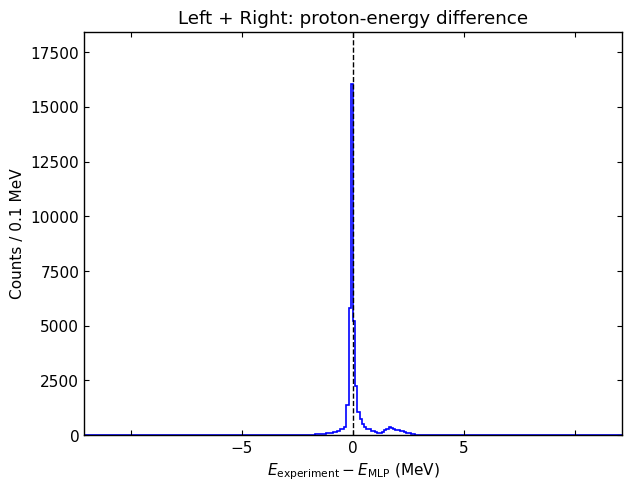

Energy difference: 39860 same-event pairs; histogram entries=39860
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/ProtonEnergyDifference.pdf


In [6]:
# 功能：输出左右臂合并的实验质子能量减 MLP 预测能量分布，保存 PDF、PNG 和分箱计数。
# 方法：复用推理结果的 ComparisonOK 同事件样本，NumPy 分箱后由 Matplotlib stairs 绘制无填充阶梯图，画布尺寸由 ENERGY_DIFFERENCE_FIGSIZE 调整。
# 注意事项：先运行第 1–4 节；能量单位 MeV；原 protonEnergy 不是真值；差值方向为实验减 MLP，
# 与已有 DeltaProtonEnergyNN 分支相反；不按能角图或激发能图范围裁剪；运行覆盖本单元格同名输出。
ENERGY_DIFFERENCE_BIN_WIDTH_MEV = 0.1  # 可在此调整 bin 宽。
ENERGY_DIFFERENCE_FIGSIZE = (6.4, 4.8)  # 画布宽、高，单位英寸。
energy_differences = []
for arm in ("Left", "Right"):
    arm_result = results[arm]
    common = arm_result["ComparisonOK"].astype(bool)
    energy_differences.append(arm_result["protonEnergy"][common]
                              - arm_result["ProtonEnergyNN"][common])
energy_differences = np.concatenate(energy_differences)
if energy_differences.size == 0:
    raise ValueError("没有同事件对照样本可用于质子能量差分布。")
# 对称范围覆盖全部有效差值，不使用显示范围再次筛选事件。
energy_difference_half_bins = max(1, int(np.ceil(
    np.max(np.abs(energy_differences)) / ENERGY_DIFFERENCE_BIN_WIDTH_MEV)))
energy_difference_limit = energy_difference_half_bins * ENERGY_DIFFERENCE_BIN_WIDTH_MEV
energy_difference_edges = np.linspace(-energy_difference_limit, energy_difference_limit,
                                      2 * energy_difference_half_bins + 1)
energy_difference_counts, _ = np.histogram(energy_differences, bins=energy_difference_edges)

energy_difference_fig, energy_difference_ax = plt.subplots(figsize=ENERGY_DIFFERENCE_FIGSIZE, layout="constrained")
energy_difference_ax.stairs(energy_difference_counts, energy_difference_edges,
                            fill=False, baseline=0.0, color="blue", linewidth=1.2, alpha=1.0)
energy_difference_ax.set(
    xlim=(-energy_difference_limit, energy_difference_limit),
    ylim=(0.0, max(1.0, 1.15 * energy_difference_counts.max())),
    xlabel=r"$E_{\mathrm{experiment}} - E_{\mathrm{MLP}}$ (MeV)",
    ylabel=f"Counts / {ENERGY_DIFFERENCE_BIN_WIDTH_MEV:g} MeV",
    title="Left + Right: proton-energy difference")
energy_difference_ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
energy_difference_ax.tick_params(direction="in", top=True, right=True)
energy_difference_ax.axvline(0.0, color="black", linestyle="--", linewidth=1.0)
energy_difference_fig.canvas.draw()
energy_difference_tick_labels = [tick.label1 for tick in energy_difference_ax.xaxis.get_major_ticks()
                                 if -energy_difference_limit <= tick.get_loc() <= energy_difference_limit
                                 and tick.label1.get_visible()]
if len(energy_difference_tick_labels) > 1:
    energy_difference_tick_labels[0].set_visible(False)
    energy_difference_tick_labels[-1].set_visible(False)
for suffix in ("pdf", "png"):
    energy_difference_fig.savefig(OUTPUT_DIR / f"ProtonEnergyDifference.{suffix}", dpi=200,
                                  bbox_inches="tight", pad_inches=0.06)
plt.show()
plt.close(energy_difference_fig)
np.savez(OUTPUT_DIR / "ProtonEnergyDifference.npz", edges_MeV=energy_difference_edges,
         counts=energy_difference_counts, difference_definition="protonEnergy - ProtonEnergyNN")
print(f"Energy difference: {energy_differences.size} same-event pairs; "
      f"histogram entries={energy_difference_counts.sum()}")
print("Saved:", OUTPUT_DIR / "ProtonEnergyDifference.pdf")


## 7. 按 Draw_8.C 生成运动学曲线

下个单元格调用 ROOT 辅助宏，质量来自 `NuclearMass::Get("10Be")` 与 `Get("1H")`。
曲线为 150 MeV/u 的 `Ex=0、3.368、6.179、10.15 MeV`，依次为参考宏的红、蓝、绿、品红，
实线、线宽1、透明度0.4；保留现有接口返回的两条运动学分支。
曲线及参数另存 CSV/JSON；不在 Python 中手写核质量或运动学公式。

In [7]:
if not KINEMATICS_MACRO.is_file():
    raise FileNotFoundError(f"缺少运动学辅助宏：{KINEMATICS_MACRO}")
if not Path(ROOT_EXECUTABLE).is_file():
    raise FileNotFoundError("未找到 ROOT 可执行文件，请修改配置中的 ROOT_EXECUTABLE。")
command = [str(ROOT_EXECUTABLE), "-l", "-b", "-q", str(KINEMATICS_MACRO)]
completed = subprocess.run(command, cwd=PROJECT_DIR, text=True, capture_output=True)
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
completed.check_returncode()
curve_path = OUTPUT_DIR / "KinematicsCurves.csv"
kinematics_configuration = json.loads((OUTPUT_DIR / "KinematicsConfiguration.json").read_text())
curve_points = np.atleast_1d(np.genfromtxt(curve_path, delimiter=",", names=True))
if len(curve_points) == 0 or len(curve_points) != kinematics_configuration["points"]:
    raise ValueError("运动学曲线点数与导出参数不一致。")
if not np.isfinite(curve_points["Theta_deg"]).all() or not np.isfinite(curve_points["ProtonEnergy_MeV"]).all():
    raise ValueError("运动学曲线含非有限值。")
curves = []
for state in np.unique(curve_points["StateIndex"]):
    state_points = curve_points[curve_points["StateIndex"] == state]
    for branch in np.unique(state_points["CurveBranch"]):
        points = state_points[state_points["CurveBranch"] == branch]
        points = np.sort(points, order="PointIndex")
        curves.append({
            "excitation": float(points["Ex_MeV"][0]), "branch": int(branch),
            "theta": points["Theta_deg"], "energy": points["ProtonEnergy_MeV"],
            "color": tuple(float(points[name][0]) for name in ("Red", "Green", "Blue")),
        })
print("Kinematics:", kinematics_configuration["beam_energy_per_u_MeV"], "MeV/u; Ex=", kinematics_configuration["excitation_MeV"])


add include path : /Users/yemingxin/anaroot/src/install/include
reading libXMLParser.so
reading libananadeko.dylib
reading libanacore.dylib
reading libanabrips.dylib
reading libanadali.dylib
reading libanasamurai.dylib
reading libanacatana.dylib
reading libanaespri.dylib
reading libanawinds.dylib
reading libanasilicons.dylib
reading libanatogaxsi.dylib
reading libanaloop.dylib
reading libanaloopexample.dylib
reading libanaloopencexample.dylib
Processing /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperimentKinematics.C...
Kinematics: 150 MeV/u, Ex=0/3.368/6.179/10.15 MeV; points=71576; output=/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output

Kinematics: 150 MeV/u; Ex= [0.0, 3.368, 6.179, 10.15]


## 8. 同事件的质子动能—角度二维图与运动学叠加

三行依次为 Left、Right、左右臂合并（Left + Right）；左列为原 `protonEnergy`，右列为 `ProtonEnergyNN`。
合并图逐 bin 相加两臂的原始计数，不取平均；各臂仍使用相同的 `ComparisonOK` 样本。
横轴显示角度 50–80°、bin 宽0.1°；事件角度筛选仍为 55–70°。动能 0–180 MeV、bin 宽0.1 MeV。
六图保持原始计数，使用共同彩虹（rainbow）对数色标，绘图区均为4:3；曲线只作理论位置对照。
显示范围外的事件计数会报告，不用显示范围重新筛选或修改预测。

Left Original {'visible_events': 19957, 'outside_display': 0}
Left NN {'visible_events': 19957, 'outside_display': 0}
Right Original {'visible_events': 19903, 'outside_display': 0}
Right NN {'visible_events': 19903, 'outside_display': 0}
Combined Original {'visible_events': 39860, 'outside_display': 0}
Combined NN {'visible_events': 39860, 'outside_display': 0}


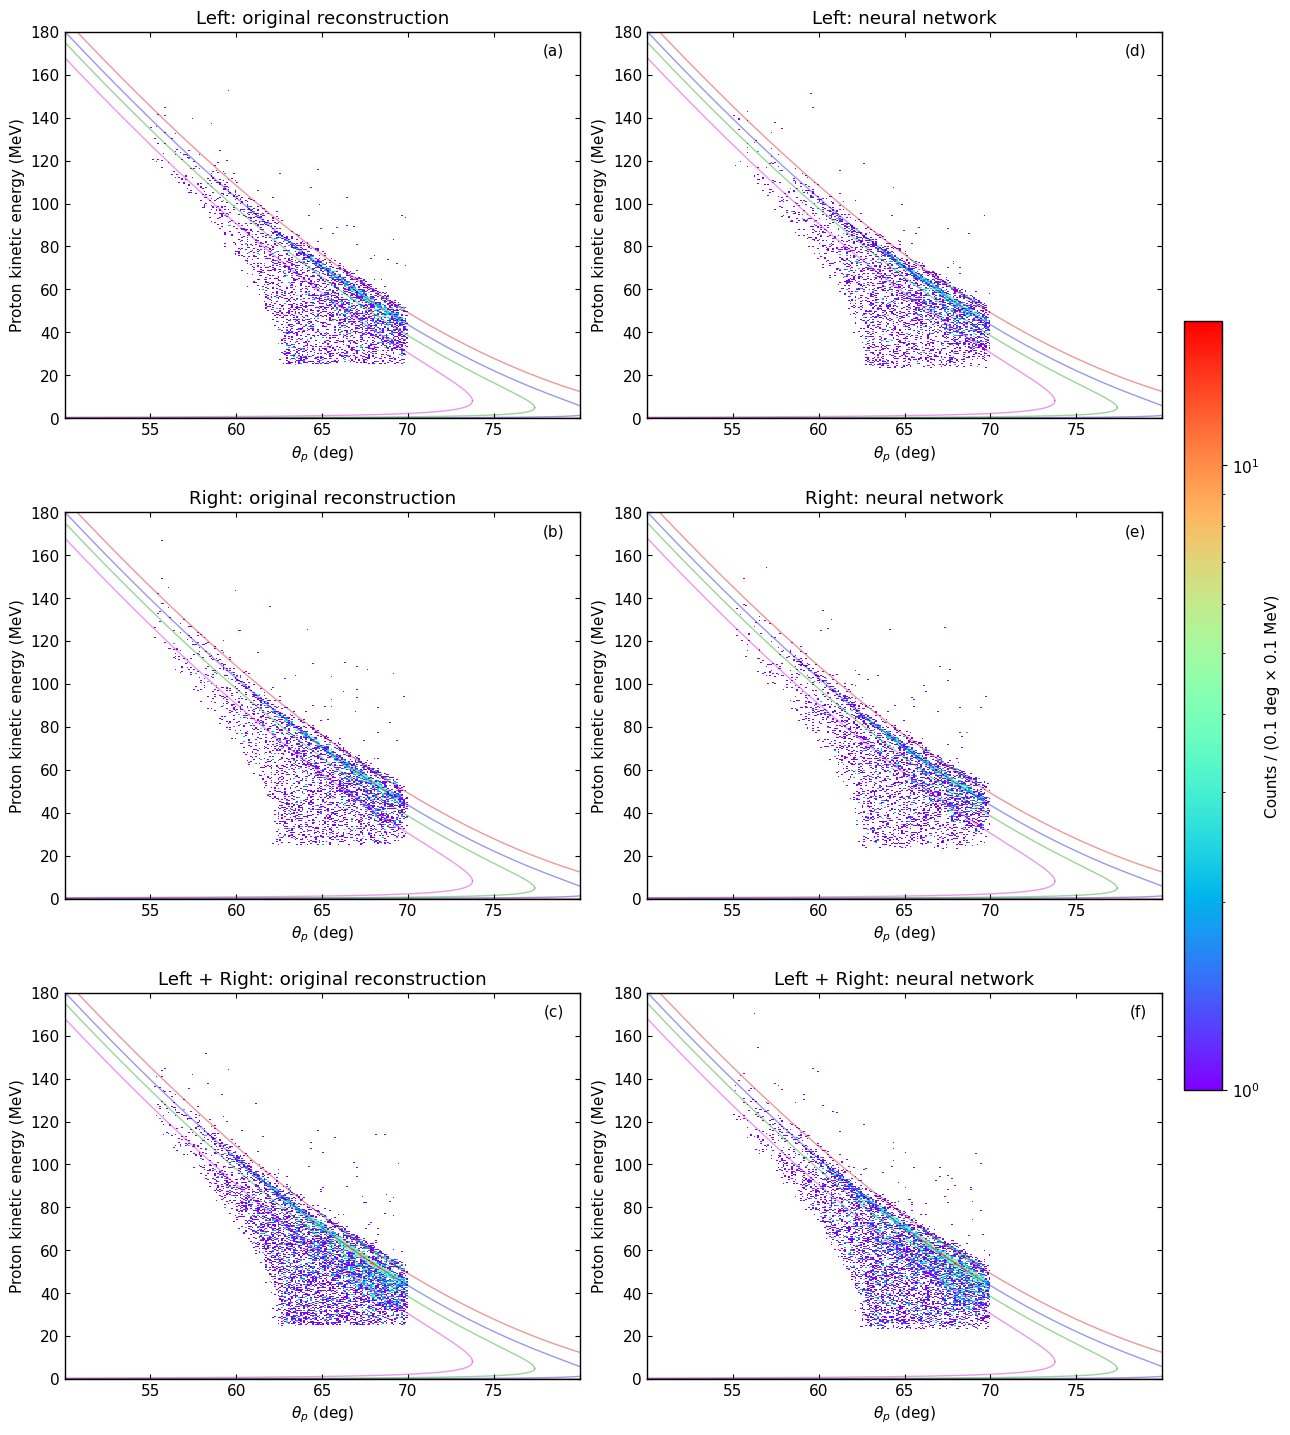

Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/ProtonEnergyAngleComparison.pdf


In [8]:
angle_edges = np.linspace(PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG,
                          int(round((PLOT_THETA_MAX_DEG - PLOT_THETA_MIN_DEG) / THETA_BIN_WIDTH_DEG)) + 1)
energy_edges = np.linspace(ENERGY_MIN_MEV, ENERGY_MAX_MEV,
                           int(round((ENERGY_MAX_MEV - ENERGY_MIN_MEV) / ENERGY_BIN_WIDTH_MEV)) + 1)
histograms = {}
plot_counts = {}
for arm in ("Left", "Right"):
    result = results[arm]
    common = result["ComparisonOK"].astype(bool)
    plot_counts[arm] = {"common_events": int(common.sum())}
    for label, branch in [("Original", "protonEnergy"), ("NN", "ProtonEnergyNN")]:
        histogram, _, _ = np.histogram2d(result["protonTheta"][common], result[branch][common],
                                         bins=(angle_edges, energy_edges))
        histograms[f"{arm}_{label}"] = histogram
        plot_counts[arm][label] = {
            "visible_events": int(histogram.sum()),
            "outside_display": int(common.sum() - histogram.sum()),
        }
        print(arm, label, plot_counts[arm][label])

# 两臂事件互斥且共用分箱；逐 bin 相加得到合并样本，保留原始计数。
plot_counts["Combined"] = {
    "common_events": sum(plot_counts[arm]["common_events"] for arm in ("Left", "Right"))
}
for label in ("Original", "NN"):
    histograms[f"Combined_{label}"] = histograms[f"Left_{label}"] + histograms[f"Right_{label}"]
    plot_counts["Combined"][label] = {
        key: sum(plot_counts[arm][label][key] for arm in ("Left", "Right"))
        for key in ("visible_events", "outside_display")
    }
    print("Combined", label, plot_counts["Combined"][label])

maximum = max(2.0, max(histogram.max() for histogram in histograms.values()))
normalization = LogNorm(vmin=1.0, vmax=maximum)
color_map = plt.get_cmap(COLOR_MAP).copy()
color_map.set_bad("white")
fig, axes = plt.subplots(3, 2, figsize=(12.8, 14.4), layout="constrained")
for row, arm in enumerate(("Left", "Right", "Combined")):
    for column, label in enumerate(("Original", "NN")):
        ax = axes[row, column]
        histogram = histograms[f"{arm}_{label}"]
        mesh = ax.pcolormesh(angle_edges, energy_edges, np.ma.masked_less_equal(histogram.T, 0),
                             cmap=color_map, norm=normalization, shading="flat", rasterized=True)
        for curve in curves:
            ax.plot(curve["theta"], curve["energy"], color=curve["color"],
                    alpha=kinematics_configuration["line_alpha"], linewidth=1, linestyle="-")
        ax.set(xlim=(PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG), ylim=(ENERGY_MIN_MEV, ENERGY_MAX_MEV),
               xlabel=r"$\theta_p$ (deg)", ylabel="Proton kinetic energy (MeV)")
        method = "original reconstruction" if label == "Original" else "neural network"
        arm_title = "Left + Right" if arm == "Combined" else arm
        ax.set_title(f"{arm_title}: {method}")
        ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
        ax.grid(False)
        ax.tick_params(direction="in", top=True, right=True)
        panel_label = chr(ord("a") + 3 * column + row)
        ax.text(0.97, 0.97, f"({panel_label})", transform=ax.transAxes, ha="right", va="top")
fig.colorbar(mesh, ax=axes.ravel().tolist(), fraction=0.035, pad=0.02,
             label=f"Counts / ({THETA_BIN_WIDTH_DEG:g} deg × {ENERGY_BIN_WIDTH_MEV:g} MeV)")
fig.canvas.draw()
for ax in axes.flat:
    lower, upper = ax.get_xlim()
    visible_labels = [tick.label1 for tick in ax.xaxis.get_major_ticks()
                      if lower <= tick.get_loc() <= upper and tick.label1.get_visible()]
    if len(visible_labels) > 1:
        visible_labels[0].set_visible(False)
        visible_labels[-1].set_visible(False)
pdf_path = OUTPUT_DIR / "ProtonEnergyAngleComparison.pdf"
fig.savefig(pdf_path, dpi=200, bbox_inches="tight", pad_inches=0.06)
fig.savefig(OUTPUT_DIR / "ProtonEnergyAngleComparison.png", dpi=180, bbox_inches="tight", pad_inches=0.06)
plt.show()
plt.close(fig)
np.savez(OUTPUT_DIR / "EnergyAngleHistograms.npz", angle_edges=angle_edges, energy_edges=energy_edges, **histograms)
plot_summary = {
    "counts": plot_counts, "theta_range_deg": [PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG],
    "energy_range_MeV": [ENERGY_MIN_MEV, ENERGY_MAX_MEV],
    "theta_bin_deg": THETA_BIN_WIDTH_DEG, "energy_bin_MeV": ENERGY_BIN_WIDTH_MEV,
    "shared_color_scale": {"vmin": 1.0, "vmax": float(maximum), "scale": "log", "normalization": "raw counts"},
    "kinematics": kinematics_configuration,
}
(OUTPUT_DIR / "PlotSummary.json").write_text(json.dumps(plot_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Saved:", pdf_path)


Left GPR: selected=19957, finite predictions=19957, outside training range=4; only flagged, not clipped
Right GPR: selected=19903, finite predictions=19903, outside training range=8; only flagged, not clipped
Original {'visible_events': 39801, 'underflow': 59, 'overflow': 0}
NN {'visible_events': 39801, 'underflow': 59, 'overflow': 0}
GPR {'visible_events': 39799, 'underflow': 61, 'overflow': 0}
Input events=39860, common valid events=39860, invalid original=0, invalid MLP=0
GPR included; invalid GPR=0, valid triplets=39860


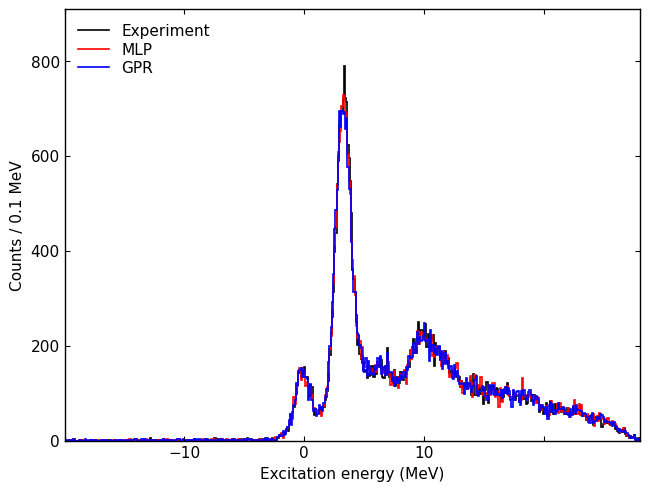

Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/ExcitationEnergyComparison.pdf


In [9]:
# 功能：必须使用原实验重建和 MLP 重建激发能；存在 GPR 模型文件时额外叠加 GPR 谱。
# 方法：复用原 ComparisonOK 事件及其实验 protonTheta；GPR 加载 Tradition 保存的模型和训练 scaler，分批预测；150 MeV/u 下调用同一缺失质量接口。
# 注意事项：必须先完成本 Notebook 的 MLP 推理和运动学格；GPR/gpr_models.pkl 不存在时跳过 GPR，存在但无效时明确报错；不拟合或重算 scaler。
# 有 GPR 时使用三者共同有效事件，无 GPR 时使用实验/MLP 共同有效事件；SourceEntry 与 espriSide 逐事件核对，原实验重建不是真值。
# 能量 MeV、坐标 mm、角度 deg；运行覆盖本单元格已有同名产物，不修改实验输入或模型。
from tempfile import TemporaryDirectory
import pickle

# MLP 是必需项；GPR 只在模型文件存在时启用，不自动训练或生成模型。
if ("results" not in globals() or any(arm not in results for arm in ("Left", "Right"))
        or any("ProtonEnergyNN" not in results[arm] or "ComparisonOK" not in results[arm]
               for arm in ("Left", "Right"))):
    raise RuntimeError("必须先完成左右臂 MLP 模型加载与实验推理，再运行激发能重建。")
GPR_MODEL_PATH = PROJECT_DIR / "GPR" / "gpr_models.pkl"
EX_HAS_GPR = GPR_MODEL_PATH.is_file()
gpr_experiment, gpr_model_records = {}, {}
if EX_HAS_GPR:
    # 仅加载自己生成且可信的 pickle；已有文件的读取或校验错误不静默忽略。
    with GPR_MODEL_PATH.open("rb") as stream:
        gpr_checkpoint = pickle.load(stream)
    if (gpr_checkpoint.get("format_version") != 1
            or list(gpr_checkpoint.get("feature_names", [])) != FEATURE_NAMES
            or list(gpr_checkpoint.get("feature_units", [])) != FEATURE_UNITS
            or gpr_checkpoint.get("target_name") != "ETrue"
            or gpr_checkpoint.get("target_unit") != "MeV" or gpr_checkpoint.get("dtype") != "float64"):
        raise ValueError("GPR 模型文件的格式、输入顺序、单位或目标不匹配。")
    experiment_gpr_models = gpr_checkpoint["models"]
    if any(arm not in experiment_gpr_models for arm in ("Left", "Right")):
        raise ValueError("GPR 模型文件未同时包含 Left/Right 两臂。")
    with GPR_MODEL_PATH.open("rb") as stream:
        gpr_hasher = hashlib.sha256()
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            gpr_hasher.update(chunk)
    gpr_checkpoint_sha256 = gpr_hasher.hexdigest()
    GPR_EX_BATCH_SIZE = 512
    for arm in ("Left", "Right"):
        saved_gp = experiment_gpr_models[arm]
        if (saved_gp.get("arm") != arm or list(saved_gp.get("feature_names", [])) != FEATURE_NAMES
                or list(saved_gp.get("feature_units", [])) != FEATURE_UNITS
                or saved_gp.get("target_name") != "ETrue" or saved_gp.get("target_unit") != "MeV"
                or saved_gp.get("dtype") != "float64"):
            raise ValueError(f"{arm} GPR 的臂、输入顺序、单位或目标定义不匹配，请重新运行 Tradition 的 GPR 格。")
        arm_result = results[arm]
        X_gp = np.column_stack([arm_result[name] for name in FEATURE_NAMES]).astype(np.float64)
        gp_prediction = np.full(len(X_gp), INVALID_VALUE, dtype=np.float64)
        gp_prediction_ok = np.zeros(len(X_gp), dtype=bool)
        for first in range(0, len(X_gp), GPR_EX_BATCH_SIZE):
            stop = min(first + GPR_EX_BATCH_SIZE, len(X_gp))
            gp_values = np.asarray(saved_gp["model"].predict(
                saved_gp["scaler"].transform(X_gp[first:stop])), dtype=np.float64).reshape(-1)
            if gp_values.shape != (stop - first,):
                raise ValueError(f"{arm} GPR 预测行数不匹配。")
            finite = np.isfinite(gp_values)
            gp_prediction[first:stop] = np.where(finite, gp_values, INVALID_VALUE)
            gp_prediction_ok[first:stop] = finite
        outside = ((X_gp < saved_gp["train_feature_min"]) | (X_gp > saved_gp["train_feature_max"]))
        gpr_experiment[arm] = {"SourceEntry": arm_result["SourceEntry"].copy(),
                               "prediction": gp_prediction, "PredictionOK": gp_prediction_ok}
        gpr_model_records[arm] = {
            "checkpoint": str(GPR_MODEL_PATH.resolve()), "sha256": gpr_checkpoint_sha256,
            "sklearn_version": gpr_checkpoint["sklearn_version"], "input_path": saved_gp["input_path"],
            "fit_events": saved_gp["fit_events"], "full_train_events": saved_gp["full_train_events"],
            "kernel": saved_gp["kernel"], "feature_names": saved_gp["feature_names"],
            "feature_units": saved_gp["feature_units"], "target_name": saved_gp["target_name"],
            "target_unit": saved_gp["target_unit"], "selected_events": int(len(X_gp)),
            "finite_predictions": int(gp_prediction_ok.sum()),
            "nonpositive_predictions": int(((gp_prediction <= 0.0) & gp_prediction_ok).sum()),
            "outside_training_range": int(outside.any(axis=1).sum()),
        }
        print(f"{arm} GPR: selected={len(X_gp)}, finite predictions={gp_prediction_ok.sum()}, "
              f"outside training range={outside.any(axis=1).sum()}; only flagged, not clipped")

else:
    print(f"未找到可选 GPR 模型：{GPR_MODEL_PATH}；本次只比较实验和 MLP。", flush=True)

EX_MIN_MEV, EX_MAX_MEV, EX_BIN_WIDTH_MEV = -20.0, 30.0, 0.1
EX_DISPLAY_RANGE_MEV = (-20.0, 28.0)  # 仅控制显示，保留原缓存分箱。
ex_edges = np.linspace(EX_MIN_MEV, EX_MAX_MEV,
                       int(round((EX_MAX_MEV - EX_MIN_MEV) / EX_BIN_WIDTH_MEV)) + 1)
ex_inputs = []
ex_source_entries, ex_sides = [], []
for arm in ("Left", "Right"):
    arm_result = results[arm]
    common = arm_result["ComparisonOK"].astype(bool)
    ex_inputs.append(np.column_stack((arm_result["protonTheta"][common],
                                      arm_result["protonEnergy"][common],
                                      arm_result["ProtonEnergyNN"][common],
                                      (gpr_experiment[arm]["prediction"][common] if EX_HAS_GPR
                                       else np.full(int(common.sum()), INVALID_VALUE, dtype=np.float64)))))
    ex_source_entries.append(arm_result["SourceEntry"][common])
    ex_sides.append(arm_result["espriSide"][common])
ex_inputs = np.concatenate(ex_inputs, axis=0)
ex_source_entries = np.concatenate(ex_source_entries)
ex_sides = np.concatenate(ex_sides)
if len(ex_inputs) == 0:
    raise ValueError("没有实验与必需 MLP 的同事件对照样本可用于激发能重建。")
# 与上方理论曲线一致；缺失质量接口要求总束流动能，10Be 的整数质量数为 10。
ex_beam_total_mev = 10.0 * float(kinematics_configuration["beam_energy_per_u_MeV"])
ex_macro_source = r"""// 功能：逐事件计算原重建、MLP、GPR 三种质子动能对应的 10Be 激发能。
// 方法：NuclearMass 的 MassAMU（u）质量和 TwoBodyKinematicsMissingMass；原样返回 SourceEntry、espriSide。
// 注意事项：输入为实验同事件角度及三种能量；束流总动能 MeV，角度 deg；失败值 -999 配合有效标志。
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/TwoBodyKinematics/TwoBodyKinematics.h"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/TwoBodyKinematics/TwoBodyKinematics.cc"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/NuclearMass/NuclearMass.h"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/NuclearMass/NuclearMass.cc"
#include "TMath.h"
#include <cmath>
#include <fstream>
#include <iomanip>
#include <stdexcept>
void ForExperimentExcitation() {
    const Double_t kInvalidValue = -999.0;
    const Double_t massBe = NuclearMass::Get("10Be").MassMeV;
    const Double_t massBeAmu = NuclearMass::Get("10Be").MassAMU;
    const Double_t massPAmu = NuclearMass::Get("1H").MassAMU;
    const Double_t beamEnergy = __BEAM_TOTAL_MEV__;
    std::ifstream input("ExcitationInputs.txt");
    std::ofstream output("ExcitationValues.csv");
    if (!input || !output) throw std::runtime_error("Cannot open excitation input/output");
    output << "SourceEntry,espriSide,ExOriginal_MeV,ExNN_MeV,ExGPR_MeV,OriginalOK,NNOK,GPROK\n"
           << std::setprecision(17);
    Long64_t sourceEntry = 0;
    Int_t side = 0;
    Double_t theta = 0.0, originalEnergy = 0.0, nnEnergy = 0.0, gpEnergy = 0.0;
    while (input >> sourceEntry >> side >> theta >> originalEnergy >> nnEnergy >> gpEnergy) {
        const Double_t energies[3] = {originalEnergy, nnEnergy, gpEnergy};
        Double_t excitation[3] = {kInvalidValue, kInvalidValue, kInvalidValue};
        Int_t valid[3] = {0, 0, 0};
        for (Int_t method = 0; method < 3; ++method) {
            if (!std::isfinite(theta) || theta < 0.0 || theta > 180.0
                || !std::isfinite(energies[method]) || energies[method] <= 0.0
                || massBe + beamEnergy - energies[method] <= 0.0) continue;
            const Double_t value = TwoBodyKinematicsMissingMass(
                massBeAmu, massPAmu, massPAmu, massBeAmu, beamEnergy, energies[method],
                std::cos(theta * TMath::DegToRad()));
            if (std::isfinite(value)) {
                excitation[method] = value;
                valid[method] = 1;
            }
        }
        output << sourceEntry << ',' << side;
        for (Int_t method = 0; method < 3; ++method) output << ',' << excitation[method];
        for (Int_t method = 0; method < 3; ++method) output << ',' << valid[method];
        output << '\n';
    }
    output.close();
    if (!input.eof() || !output) throw std::runtime_error("Excitation data transfer failed");
}
""".replace("__BEAM_TOTAL_MEV__", format(ex_beam_total_mev, ".17g"))
# 独立 ROOT 进程沿用已有 C++ 接口；临时文件在读取结果后自动清理，无需 PyROOT。
with TemporaryDirectory(prefix="for_experiment_excitation_") as ex_temp:
    ex_temp_path = Path(ex_temp)
    ex_transfer = np.column_stack((ex_source_entries, ex_sides, ex_inputs))
    np.savetxt(ex_temp_path / "ExcitationInputs.txt", ex_transfer,
               fmt=["%d", "%d"] + ["%.17g"] * 4)
    ex_macro = ex_temp_path / "ForExperimentExcitation.C"
    ex_macro.write_text(ex_macro_source, encoding="utf-8")
    ex_run = subprocess.run([str(ROOT_EXECUTABLE), "-l", "-b", "-q", str(ex_macro)],
                            cwd=ex_temp_path, text=True, capture_output=True)
    if ex_run.returncode:
        print(ex_run.stdout)
        print(ex_run.stderr)
    ex_run.check_returncode()
    ex_values = np.atleast_1d(np.genfromtxt(ex_temp_path / "ExcitationValues.csv",
                                           delimiter=",", names=True, dtype=None, encoding="utf-8"))
if len(ex_values) != len(ex_inputs):
    raise ValueError("激发能输出行数与输入不一致，不能保证事件对齐。")
if (not np.array_equal(ex_values["SourceEntry"], ex_source_entries)
        or not np.array_equal(ex_values["espriSide"], ex_sides)):
    raise ValueError("激发能输出的 SourceEntry/espriSide 与实验输入不一致。")
ex_original_ok = ex_values["OriginalOK"].astype(bool)
ex_nn_ok = ex_values["NNOK"].astype(bool)
ex_gpr_ok = ex_values["GPROK"].astype(bool)
ex_pair_ok = ex_original_ok & ex_nn_ok  # 保留旧两种方法的有效标志供审计。
ex_triplet_ok = ex_pair_ok & ex_gpr_ok
ex_comparison_ok = ex_triplet_ok if EX_HAS_GPR else ex_pair_ok
ex_spectrum_methods = [
    ("Original", "ExOriginal_MeV", "#000000", "Experiment"),
    ("NN", "ExNN_MeV", "#FF0000", "MLP"),
]
if EX_HAS_GPR:
    ex_spectrum_methods.append(("GPR", "ExGPR_MeV", "#0000FF", "GPR"))
ex_histograms, ex_statistics = {}, {}
for method, branch, _, _ in ex_spectrum_methods:
    values = ex_values[branch][ex_comparison_ok]
    ex_histograms[method], _ = np.histogram(values, bins=ex_edges)
    ex_statistics[method] = {
        "visible_events": int(ex_histograms[method].sum()),
        "underflow": int((values < EX_MIN_MEV).sum()),
        "overflow": int((values > EX_MAX_MEV).sum()),
    }
    print(method, ex_statistics[method])
print(f"Input events={len(ex_inputs)}, common valid events={ex_comparison_ok.sum()}, "
      f"invalid original={(~ex_original_ok).sum()}, invalid MLP={(~ex_nn_ok).sum()}")
if EX_HAS_GPR:
    print(f"GPR included; invalid GPR={(~ex_gpr_ok).sum()}, valid triplets={ex_triplet_ok.sum()}")
if not ex_comparison_ok.any():
    raise ValueError("没有当前启用方法均有效的同事件，不能绘制激发能谱对照。")

ex_fig, ex_ax = plt.subplots(figsize=(6.4, 4.8), layout="constrained")
for method, _, color, label in ex_spectrum_methods:
    ex_ax.stairs(ex_histograms[method], ex_edges, fill=False, baseline=0.0,
                 color=color, linewidth=1.2, alpha=1.0, label=label)
ex_ax.set(xlim=EX_DISPLAY_RANGE_MEV,
          ylim=(0.0, max(1.0, 1.15 * max(h.max() for h in ex_histograms.values()))),
          xlabel="Excitation energy (MeV)",
          ylabel=f"Counts / {ex_edges[1] - ex_edges[0]:g} MeV")
ex_ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
ex_ax.tick_params(direction="in", top=True, right=True)
ex_ax.legend(loc="upper left", frameon=False, labelspacing=0.25)
ex_fig.canvas.draw()
ex_tick_labels = [tick.label1 for tick in ex_ax.xaxis.get_major_ticks()
                  if EX_DISPLAY_RANGE_MEV[0] <= tick.get_loc() <= EX_DISPLAY_RANGE_MEV[1] and tick.label1.get_visible()]
if len(ex_tick_labels) > 1:
    ex_tick_labels[0].set_visible(False)
    ex_tick_labels[-1].set_visible(False)
for suffix in ("pdf", "png"):
    ex_fig.savefig(OUTPUT_DIR / f"ExcitationEnergyComparison.{suffix}", dpi=200,
                   bbox_inches="tight", pad_inches=0.06)
plt.show()
plt.close(ex_fig)
# 必需的实验/MLP 字段始终保存；只有本次启用 GPR 时才保存 GPR 字段，防止残留旧结果。
ex_cache = {
    "edges_MeV": ex_edges, "Original": ex_histograms["Original"], "NN": ex_histograms["NN"],
    "SourceEntry": ex_source_entries, "espriSide": ex_sides,
    "ExOriginal_MeV": ex_values["ExOriginal_MeV"], "ExNN_MeV": ex_values["ExNN_MeV"],
    "ProtonTheta_deg": ex_inputs[:, 0], "ProtonEnergyOriginal_MeV": ex_inputs[:, 1],
    "ProtonEnergyMLP_MeV": ex_inputs[:, 2], "OriginalOK": ex_original_ok, "NNOK": ex_nn_ok,
    "PairOK": ex_pair_ok, "ComparisonOK": ex_comparison_ok, "GPRIncluded": np.asarray(EX_HAS_GPR),
}
if EX_HAS_GPR:
    ex_cache.update({"GPR": ex_histograms["GPR"], "ExGPR_MeV": ex_values["ExGPR_MeV"],
                     "ProtonEnergyGPR_MeV": ex_inputs[:, 3], "GPROK": ex_gpr_ok,
                     "TripletOK": ex_triplet_ok})
np.savez(OUTPUT_DIR / "ExcitationEnergyComparison.npz", **ex_cache)
ex_summary = {
    "reaction": "10Be(p,p)10Be", "beam_energy_total_MeV": ex_beam_total_mev,
    "theta_selection_deg": [THETA_MIN_DEG, THETA_MAX_DEG],
    "range_MeV": [EX_MIN_MEV, EX_MAX_MEV], "display_range_MeV": list(EX_DISPLAY_RANGE_MEV),
    "bin_width_MeV": EX_BIN_WIDTH_MEV,
    "input_pairs": int(len(ex_inputs)), "valid_pairs": int(ex_pair_ok.sum()),
    "gpr_included": bool(EX_HAS_GPR), "common_events": int(ex_comparison_ok.sum()),
    "valid_triplets": int(ex_triplet_ok.sum()) if EX_HAS_GPR else None,
    "invalid_GPR": int((~ex_gpr_ok).sum()) if EX_HAS_GPR else None,
    "invalid_original": int((~ex_original_ok).sum()), "invalid_NN": int((~ex_nn_ok).sum()),
    "normalization": "raw counts; same experimental events valid for all enabled methods",
    "gpr_models": gpr_model_records,
    "counts": ex_statistics,
}
(OUTPUT_DIR / "ExcitationEnergySummary.json").write_text(
    json.dumps(ex_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Saved:", OUTPUT_DIR / "ExcitationEnergyComparison.pdf")


## 输出

- `Predicted_Left.root`、`Predicted_Right.root`：两臂通过 cut 的实验事件、模型预测、原重建和有效性标志；同时保留统一的 NaIBarID 与实验局部 espriNaiBarId。
- `ExperimentSummary.json`：实验来源、逐步 cut 计数、臂映射、模型 SHA256 与训练参数。
- `KinematicsCurves.csv`、`KinematicsConfiguration.json`：现有 C++ 接口生成的运动学曲线及参数。
- `ProtonEnergyAngleComparison.pdf/.png`：三行两列的同事件能角对照图（Left、Right、左右臂合并）。
- `EnergyAngleHistograms.npz`、`PlotSummary.json`：六图原始计数（含 Combined_Original、Combined_NN）、分箱与可见事件统计，供以后仅重画。

- `ExcitationEnergyComparison.pdf/.png`：左右臂合并的原重建/MLP 及可选 GPR 的激发能叠加阶梯式直方图（无填充）（显示 −20～28 MeV，bin 宽0.1 MeV）。
- `ExcitationEnergyComparison.npz`、`ExcitationEnergySummary.json`：同事件激发能、PairOK、当前启用方法的 ComparisonOK、GPRIncluded；启用 GPR 时另含 TripletOK 和 GPR 模型来源。

- `ProtonEnergyDifference.pdf/.png`：左右臂合并的实验能量减 MLP 预测能量的无填充阶梯直方图（bin 宽 0.1 MeV，范围自动覆盖全部差值）。
- `ProtonEnergyDifference.npz`：能量差分箱边界、原始计数和差值方向，供以后仅重画。

- `ExcitationPeakGaussianFits.pdf/.png`、`.json`、`.csv`：最后一个代码单元格输出的一行两列（实验、MLP）或三列（另含 GPR）的局部单高斯拟合图、参数与统计误差。

从上到下运行。本 Notebook 的模型应用结果需要结合实验 NaI 标定和数据/模拟响应进一步检查；
原重建结果与运动学曲线均不作为模型训练标签或实验真值。

## 9. 实验、MLP 及可选 GPR：各峰独立单高斯拟合

实验和 MLP 为必需项；缓存含 GPR 时增加第三列，否则只显示实验与 MLP 两列。
复用 `ExcitationEnergyComparison.npz`：有 GPR 时共用 `TripletOK`，无 GPR 时共用 `PairOK`。
兼容原有两谱缓存；含已计算 GPR 的缓存无需模型文件即可重画，但不得缺失必需的实验或 MLP 数据。
后两种方法是模拟训练模型对实验事件的重建，不是独立模拟真值谱。
基态 −1.0～1.0 MeV、第一激发态 2.3～4.3 MeV，分别独立单高斯拟合；无本底、无相邻峰、无共享峰参数。
保留 iminuit MIGRAD 的窗口归一化非分箱扩展似然及 HESSE 统计误差。
画布随方法数调整为 12.8×4.8 或 19.2×4.8 英寸，各绘图区为 4:3；显示范围 −20～28 MeV。
局部 σ 不是真值残差分辨率。输出沿用 `ExcitationPeakGaussianFits.pdf/.png/.json/.csv`。


Original gs   : mu=-0.0338, sigma=0.6788 +/- 0.0255 MeV, deviance/ndf=6.15
Original first: mu=3.3129, sigma=0.6698 +/- 0.0111 MeV, deviance/ndf=0.20
MLP      gs   : mu=-0.0608, sigma=0.7361 +/- 0.0320 MeV, deviance/ndf=6.71
MLP      first: mu=3.2919, sigma=0.6944 +/- 0.0124 MeV, deviance/ndf=0.32
GPR      gs   : mu=-0.0766, sigma=0.7336 +/- 0.0317 MeV, deviance/ndf=6.65
GPR      first: mu=3.2641, sigma=0.7135 +/- 0.0134 MeV, deviance/ndf=1.79


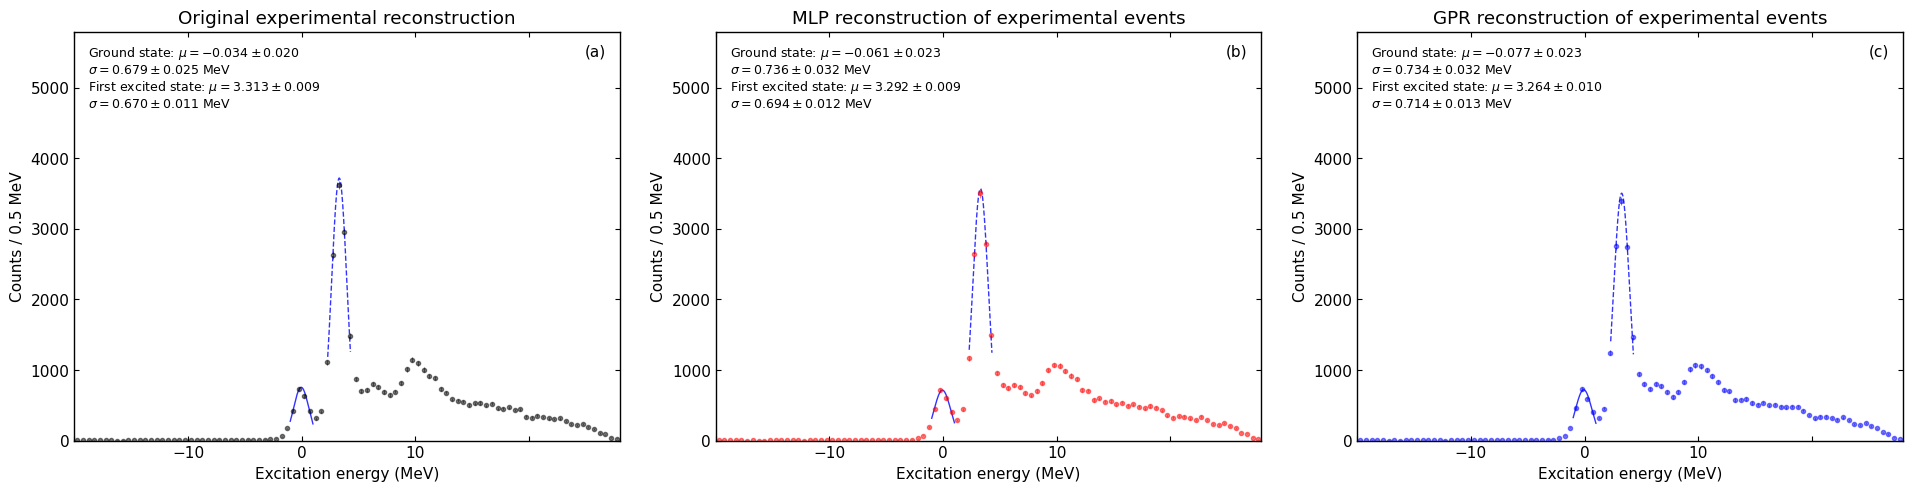

Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ForExperiment_output/ExcitationPeakGaussianFits.pdf


In [10]:
# 功能：合并左右臂，必须对实验/MLP 激发能做局部单高斯拟合；缓存含 GPR 时增加第三列，否则一行两列。
# 方法：读取两谱或三谱 NPZ 同事件缓存，按 GPRIncluded 及有效标志决定方法和共同事件；iminuit MIGRAD 做窗口归一化的单高斯非分箱扩展似然拟合，HESSE 给出统计误差；数据点和误差棒 alpha=0.5。
# 注意事项：必须有实验和 MLP 缓存；GPR 可选，不依赖 GPR 模型文件重画已有缓存；顺序为实验、MLP、可选 GPR。
# 不加本底、不加相邻峰、不共享峰参数；单位 MeV；局部 sigma 不是本征分辨率；运行覆盖本单元格同名输出。
import csv
from iminuit import Minuit
from scipy.special import ndtr, xlogy

PEAK_FIT_WINDOWS_MEV = {"gs": (-1.0, 1.0), "first": (2.3, 4.3)}
PEAK_FIT_DISPLAY_MEV = (-20.0, 28.0)
PEAK_FIT_BIN_WIDTH_MEV = 0.5
PEAK_FIT_SIGMA_LIMITS_MEV = (0.1, 2.0)
peak_fit_input = OUTPUT_DIR / "ExcitationEnergyComparison.npz"
with np.load(peak_fit_input, allow_pickle=False) as peak_saved:
    required = {"PairOK", "ExOriginal_MeV", "ExNN_MeV"}
    if not required.issubset(peak_saved.files):
        raise ValueError("激发能缓存必须包含实验、MLP 及 PairOK，请先运行前一个代码单元格。")
    gpr_fields = {"TripletOK", "ExGPR_MeV"}
    peak_has_gpr = (bool(peak_saved["GPRIncluded"].item()) if "GPRIncluded" in peak_saved.files
                    else gpr_fields.issubset(peak_saved.files))
    if peak_has_gpr and not gpr_fields.issubset(peak_saved.files):
        raise ValueError("缓存标记启用 GPR，但缺少 GPR 激发能或有效标志，请重新运行前一个代码单元格。")
    peak_mask_name = "TripletOK" if peak_has_gpr else "PairOK"
    peak_pair_ok = peak_saved[peak_mask_name].astype(bool)
    peak_arrays = {
        "Original": np.asarray(peak_saved["ExOriginal_MeV"][peak_pair_ok], dtype=np.float64),
        "MLP": np.asarray(peak_saved["ExNN_MeV"][peak_pair_ok], dtype=np.float64),
    }
    if peak_has_gpr:
        peak_arrays["GPR"] = np.asarray(peak_saved["ExGPR_MeV"][peak_pair_ok], dtype=np.float64)
peak_methods = [
    ("Original", "Original experimental reconstruction", "#000000"),
    ("MLP", "MLP reconstruction of experimental events", "#FF0000"),
]
if peak_has_gpr:
    peak_methods.append(("GPR", "GPR reconstruction of experimental events", "#0000FF"))
PEAK_FIT_FIGSIZE = (6.4 * len(peak_methods), 4.8)  # 一行两列或三列；各图框保持 4:3。
peak_fit_labels = {"gs": "Ground state", "first": "First excited state"}


def fit_local_peak(values, bounds):
    """每个峰独立做窗口归一化的单高斯扩展似然拟合。"""
    low, high = bounds
    data = values[(values >= low) & (values <= high)]
    count = len(data)
    if count < 4:
        raise ValueError(f"拟合窗口 {bounds} 内事件不足：{count}")

    def nll(n, mu, sigma):
        norm = ndtr((high - mu) / sigma) - ndtr((low - mu) / sigma)
        return (n - count * np.log(n)
                + count * (np.log(sigma) + 0.5 * np.log(2.0 * np.pi) + np.log(norm))
                + 0.5 * np.sum(((data - mu) / sigma) ** 2))

    fit = Minuit(nll, n=count, mu=(low + high) / 2.0, sigma=0.65)
    fit.errordef = Minuit.LIKELIHOOD
    fit.limits["n"] = (0.0, 2.0 * count)
    fit.limits["mu"] = (low, high)
    fit.limits["sigma"] = PEAK_FIT_SIGMA_LIMITS_MEV
    fit.migrad()
    fit.hesse()
    if not fit.valid or not fit.accurate or fit.fmin.has_parameters_at_limit:
        raise RuntimeError(f"窗口 {bounds} 的拟合或误差需要检查：{fit.fmin}")
    mu, sigma = fit.values["mu"], fit.values["sigma"]
    edges = np.linspace(low, high, int(round((high - low) / PEAK_FIT_BIN_WIDTH_MEV)) + 1)
    norm = ndtr((high - mu) / sigma) - ndtr((low - mu) / sigma)
    expected = fit.values["n"] * np.diff(ndtr((edges - mu) / sigma)) / norm
    observed = np.histogram(data, bins=edges)[0]
    deviance = 2.0 * np.sum(expected - observed + xlogy(observed, observed / expected))
    ndf = len(observed) - fit.nfit
    return {
        "range_MeV": list(bounds), "fit_events": count,
        "mu_MeV": float(mu), "mu_err_MeV": float(fit.errors["mu"]),
        "sigma_MeV": float(sigma), "sigma_err_MeV": float(fit.errors["sigma"]),
        "yield": float(fit.values["n"]), "yield_err": float(fit.errors["n"]),
        "covariance_order": ["mu", "sigma"],
        "covariance": np.asarray(fit.covariance)[1:, 1:].tolist(),
        "converged": bool(fit.valid), "accurate_covariance": bool(fit.accurate),
        "parameters_at_limit": bool(fit.fmin.has_parameters_at_limit), "edm": float(fit.fmin.edm),
        "poisson_deviance": float(deviance), "ndf": ndf,
        "deviance_per_ndf": float(deviance / ndf),
    }


peak_fit_results = {
    method: {state: fit_local_peak(values, bounds)
             for state, bounds in PEAK_FIT_WINDOWS_MEV.items()}
    for method, values in peak_arrays.items()
}
peak_plot_edges = np.linspace(*PEAK_FIT_DISPLAY_MEV,
    int(round((PEAK_FIT_DISPLAY_MEV[1] - PEAK_FIT_DISPLAY_MEV[0]) / PEAK_FIT_BIN_WIDTH_MEV)) + 1)
peak_plot_bin_width = float(peak_plot_edges[1] - peak_plot_edges[0])
peak_plot_centers = (peak_plot_edges[:-1] + peak_plot_edges[1:]) / 2.0
peak_plot_counts = {method: np.histogram(values, bins=peak_plot_edges)[0]
                    for method, values in peak_arrays.items()}
peak_plot_ymax = max(1.0, 1.6 * max(counts.max() for counts in peak_plot_counts.values()))
peak_fit_fig, peak_fit_axes = plt.subplots(1, len(peak_methods), figsize=PEAK_FIT_FIGSIZE, layout="constrained")
for column, (method, title, color) in enumerate(peak_methods):
    ax = peak_fit_axes[column]
    counts = peak_plot_counts[method]
    ax.errorbar(peak_plot_centers, counts, yerr=np.sqrt(counts), fmt="o", color=color,
                markersize=3.0, elinewidth=0.7, capsize=0, linestyle="none", alpha=0.5)
    annotation = []
    for state, linestyle in (("gs", "-"), ("first", "--")):
        result = peak_fit_results[method][state]
        low, high = result["range_MeV"]
        x = np.linspace(low, high, 400)
        mu, sigma = result["mu_MeV"], result["sigma_MeV"]
        norm = ndtr((high - mu) / sigma) - ndtr((low - mu) / sigma)
        curve = result["yield"] * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
        curve *= peak_plot_bin_width / (np.sqrt(2.0 * np.pi) * sigma * norm)
        ax.plot(x, curve, color="blue", linewidth=1.0, alpha=0.8, linestyle=linestyle)
        annotation.append(
            f"{peak_fit_labels[state]}: "
            rf"$\mu={mu:.3f}\pm{result['mu_err_MeV']:.3f}$" "\n"
            rf"$\sigma={sigma:.3f}\pm{result['sigma_err_MeV']:.3f}$ MeV")
        print(f"{method:8s} {state:5s}: mu={mu:.4f}, sigma={sigma:.4f} "
              f"+/- {result['sigma_err_MeV']:.4f} MeV, "
              f"deviance/ndf={result['deviance_per_ndf']:.2f}")
    ax.text(0.025, 0.97, "\n".join(annotation), transform=ax.transAxes,
            ha="left", va="top", fontsize=9)
    ax.text(0.975, 0.97, f"({chr(97 + column)})", transform=ax.transAxes,
            ha="right", va="top")
    ax.set(xlim=PEAK_FIT_DISPLAY_MEV, ylim=(0.0, peak_plot_ymax),
           xlabel="Excitation energy (MeV)", ylabel=f"Counts / {peak_plot_bin_width:g} MeV", title=title)
    ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
    ax.tick_params(direction="in", top=True, right=True)
peak_fit_fig.canvas.draw()
for ax in peak_fit_axes:
    low, high = ax.get_xlim()
    labels = [tick.label1 for tick in ax.xaxis.get_major_ticks()
              if low <= tick.get_loc() <= high and tick.label1.get_visible()]
    if len(labels) > 1:
        labels[0].set_visible(False)
        labels[-1].set_visible(False)
for suffix in ("pdf", "png"):
    peak_fit_fig.savefig(OUTPUT_DIR / f"ExcitationPeakGaussianFits.{suffix}", dpi=200,
                         bbox_inches="tight", pad_inches=0.06)
plt.show()
plt.close(peak_fit_fig)
peak_fit_summary = {
    "input": str(peak_fit_input.resolve()),
    "input_sha256": hashlib.sha256(peak_fit_input.read_bytes()).hexdigest(),
    "common_events": int(peak_pair_ok.sum()), "fit_windows_MeV": PEAK_FIT_WINDOWS_MEV,
    "fit_method": "iminuit MIGRAD; independent window-normalized unbinned extended Gaussian likelihood; no background",
    "error_method": "iminuit HESSE; statistical errors only",
    "display_range_MeV": list(PEAK_FIT_DISPLAY_MEV), "display_bin_width_MeV": peak_plot_bin_width,
    "comparison": "Original and simulation-trained MLP, plus optional GPR, on the same experimental events",
    "methods": list(peak_arrays), "gpr_included": bool(peak_has_gpr), "event_mask": peak_mask_name,
    "fits": peak_fit_results,
}
(OUTPUT_DIR / "ExcitationPeakGaussianFits.json").write_text(
    json.dumps(peak_fit_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
with (OUTPUT_DIR / "ExcitationPeakGaussianFits.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow(["method", "state", "fit_min_MeV", "fit_max_MeV", "fit_events",
                     "mu_MeV", "mu_err_MeV", "sigma_MeV", "sigma_err_MeV", "deviance_per_ndf"])
    for method, states in peak_fit_results.items():
        for state, result in states.items():
            writer.writerow([method, state, *result["range_MeV"], result["fit_events"],
                             result["mu_MeV"], result["mu_err_MeV"], result["sigma_MeV"],
                             result["sigma_err_MeV"], result["deviance_per_ndf"]])
print("Saved:", OUTPUT_DIR / "ExcitationPeakGaussianFits.pdf")
